# Using the final model
The final model is the **ridge regression** (`reconstruct_methods.ridge`): one model per gender and position group, inputs are the low-minute per-90 as z-scores against the distribution at that many minutes (plus minutes-aware interactions), output is the estimated full-season per-90 of every volume stat. Rates are then rebuilt from those volumes.

**Part 1** checks it on players whose real full season is known (out-of-fold). **Part 2** applies it to real low-minute player-seasons. In both, the question is the same: what do the distributions look like before and after the model, next to the distribution of high-minute players?

Reading the plots: **blue fill = high-minute players** (900+ minutes, full-season per-90). **Grey outline = the raw low-minute per-90.** **Orange outline = the model's estimate.**

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
# make the repo root importable no matter which folder the notebook is opened from
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "low_minute_player_analysis").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from low_minute_player_analysis import notebook_helpers as nh
from low_minute_player_analysis import reconstruct_methods as rm
from low_minute_player_analysis import temporal_methods as tm
from low_minute_player_analysis import reconstruction_eval as ev

nh.apply_style()
r = nh.load_results("results")         # out-of-fold scores for every group, gender and method
V, R = nh.volume(r), nh.rates(r)       # volume stats / rates rebuilt from the estimated volumes
P = nh.load_paired("results")          # paired differences vs the final ridge, with bootstrap intervals
nh.describe(r)
from low_minute_player_analysis import apply_model as am
try:
    from low_minute_player_analysis import common
    con = common.connect()
    DB = True
except Exception as e:                      # no credentials / no network: the DB-only cells are skipped
    con, DB = None, False
    print("database not available, skipping database cells:", type(e).__name__)

79,101 scored rows | genders ['female', 'male'] | 7 groups | checkpoints [np.int64(250), np.int64(500), np.int64(750)] | methods ['raw', 'shrink', 'ridge', 'knn', 'ot_1d', 'ot_joint', 'ot_group', 'kalman', 'kalman_blend', 'ridge_kalman', 'gru']
volume stats scored: 113 | rebuilt rates scored: 74


## Part 1. Validation: held-out players replayed at low minutes (male Wingers, live run)
Each point is a player-season that went on to play 900+ minutes, seen only through its first matches; the model never saw that player.

In [2]:
pool, stems, est = nh.demo_group("male", "Wingers", ["raw", "ridge"])
for m in ["raw", "ridge"]:
    print(f"{m:6s} median nrmse @250/500/750:",
          [round(float(nh.nrmse_per_stat(pool, est[m], b).median()), 3) for b in (250, 500, 750)])

raw    median nrmse @250/500/750: [1.378, 0.627, 0.451]
ridge  median nrmse @250/500/750: [0.745, 0.519, 0.417]


### Distributions by stat (the 250 bin: 0-375 minutes of data)
Left: raw low-minute per-90 against the high-minute distribution. Right: the model's estimate for the same players against the same distribution.

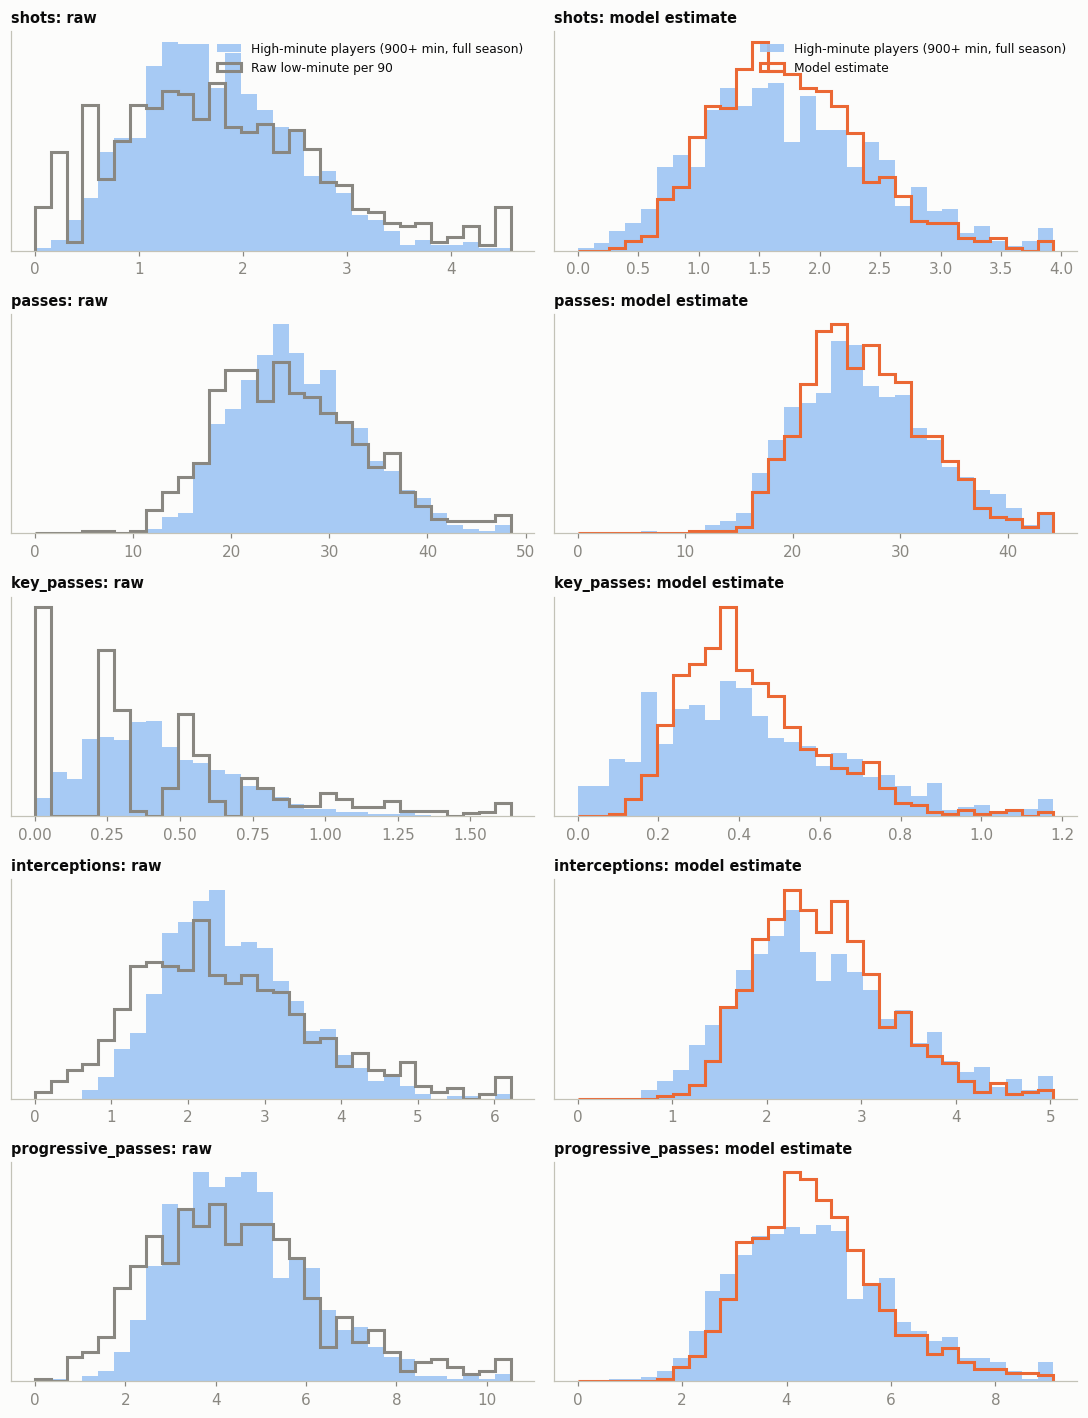

In [3]:
stat_list = ["shots", "passes", "key_passes", "interceptions", "progressive_passes"]
stat_list = [s for s in stat_list if s in stems]
rows = pool[pool["bin"] == 250].groupby(["player_id", "year"]).tail(1).index
fig, axes = plt.subplots(len(stat_list), 2, figsize=(10, 2.6 * len(stat_list)))
for i, s in enumerate(stat_list):
    high = pool.loc[rows, f"full_{s}"]
    nh.overlay_hist(axes[i, 0], high, est["raw"].loc[rows, s], "Raw low-minute per 90", nh.COLORS["raw"], title=f"{s}: raw")
    nh.overlay_hist(axes[i, 1], high, est["ridge"].loc[rows, s], "Model estimate", nh.COLORS["ridge"], title=f"{s}: model estimate")
axes[0, 0].legend(fontsize=8, loc="upper right"); axes[0, 1].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

In [4]:
s = "shots"
summ = {"high-minute (truth)": pool.loc[rows, f"full_{s}"], "raw low-minute": est["raw"].loc[rows, s], "model estimate": est["ridge"].loc[rows, s]}
display(nh.dist_summary(summ).round(3))

,n,mean,sd,share_zero,p10,median,p90
high-minute (truth),896.0,1.763,0.748,0.000,0.832,1.683,2.767
raw low-minute,896.0,1.795,1.010,0.018,0.552,1.687,3.065
model estimate,896.0,1.752,0.607,0.000,1.006,1.697,2.544


The raw distribution is **too wide** (noise from the small sample) and has a spike at 0. The model's estimate removes the noise and lands near the right centre, but it is **narrower than the true high-minute distribution**: it predicts each player's expected value, and expected values vary less than outcomes. That is the price of minimising the per-player error; methods that match the spread (optimal transport) pay for it in per-player RMSE (see the comparison notebook).

### How it changes with the amount of data (shots)

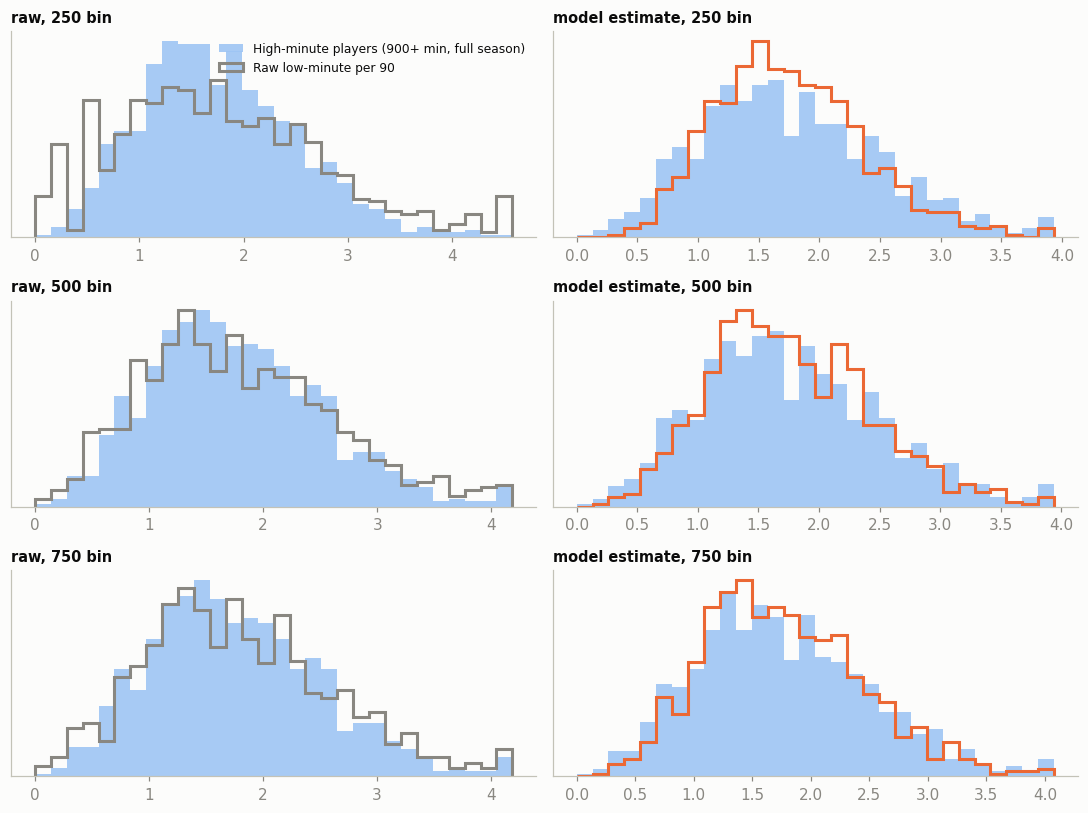

In [5]:
s = "shots"
fig, axes = plt.subplots(3, 2, figsize=(10, 7.5))
for i, b in enumerate((250, 500, 750)):
    r_ = pool[pool["bin"] == b].groupby(["player_id", "year"]).tail(1).index
    nh.overlay_hist(axes[i, 0], pool.loc[r_, f"full_{s}"], est["raw"].loc[r_, s], "Raw low-minute per 90", nh.COLORS["raw"], title=f"raw, {b} bin")
    nh.overlay_hist(axes[i, 1], pool.loc[r_, f"full_{s}"], est["ridge"].loc[r_, s], "Model estimate", nh.COLORS["ridge"], title=f"model estimate, {b} bin")
axes[0, 0].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

With more minutes the raw distribution tightens toward the truth by itself and the model's estimate widens toward it: the model trusts the player's own data more as it grows.

## Part 2. Real low-minute players
The model is fitted on **all** of a group's 900+ minute player-seasons (every prefix) and applied to player-seasons that ended with **150 to 750 minutes** in total, using the whole season as the low-minute sample. This part needs the database.

In [6]:
assert DB, "Part 2 needs the database connection"
GENDER, GROUP = "male", "Wingers"
pool_all, stems = am.fit_data(GENDER, GROUP)
low = am.low_minute_seasons(con, GENDER, GROUP, stems, min_minutes=150, max_minutes=750)
estimate = am.predict(pool_all, low, stems)
truth_seasons = pool_all.drop_duplicates(["player_id", "year"])
print(f"{len(truth_seasons)} high-minute player-seasons used to fit; {len(low)} real low-minute player-seasons predicted")
display(low["actual_minutes"].describe().round(0).to_frame("minutes of the low-minute seasons").T)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

896 high-minute player-seasons used to fit; 1319 real low-minute player-seasons predicted


,count,mean,std,min,25%,50%,75%,max
minutes of the low-minute seasons,1319.0,432.0,176.0,150.0,275.0,419.0,585.0,750.0


### Distributions by stat: raw low-minute, model estimate, and high-minute players

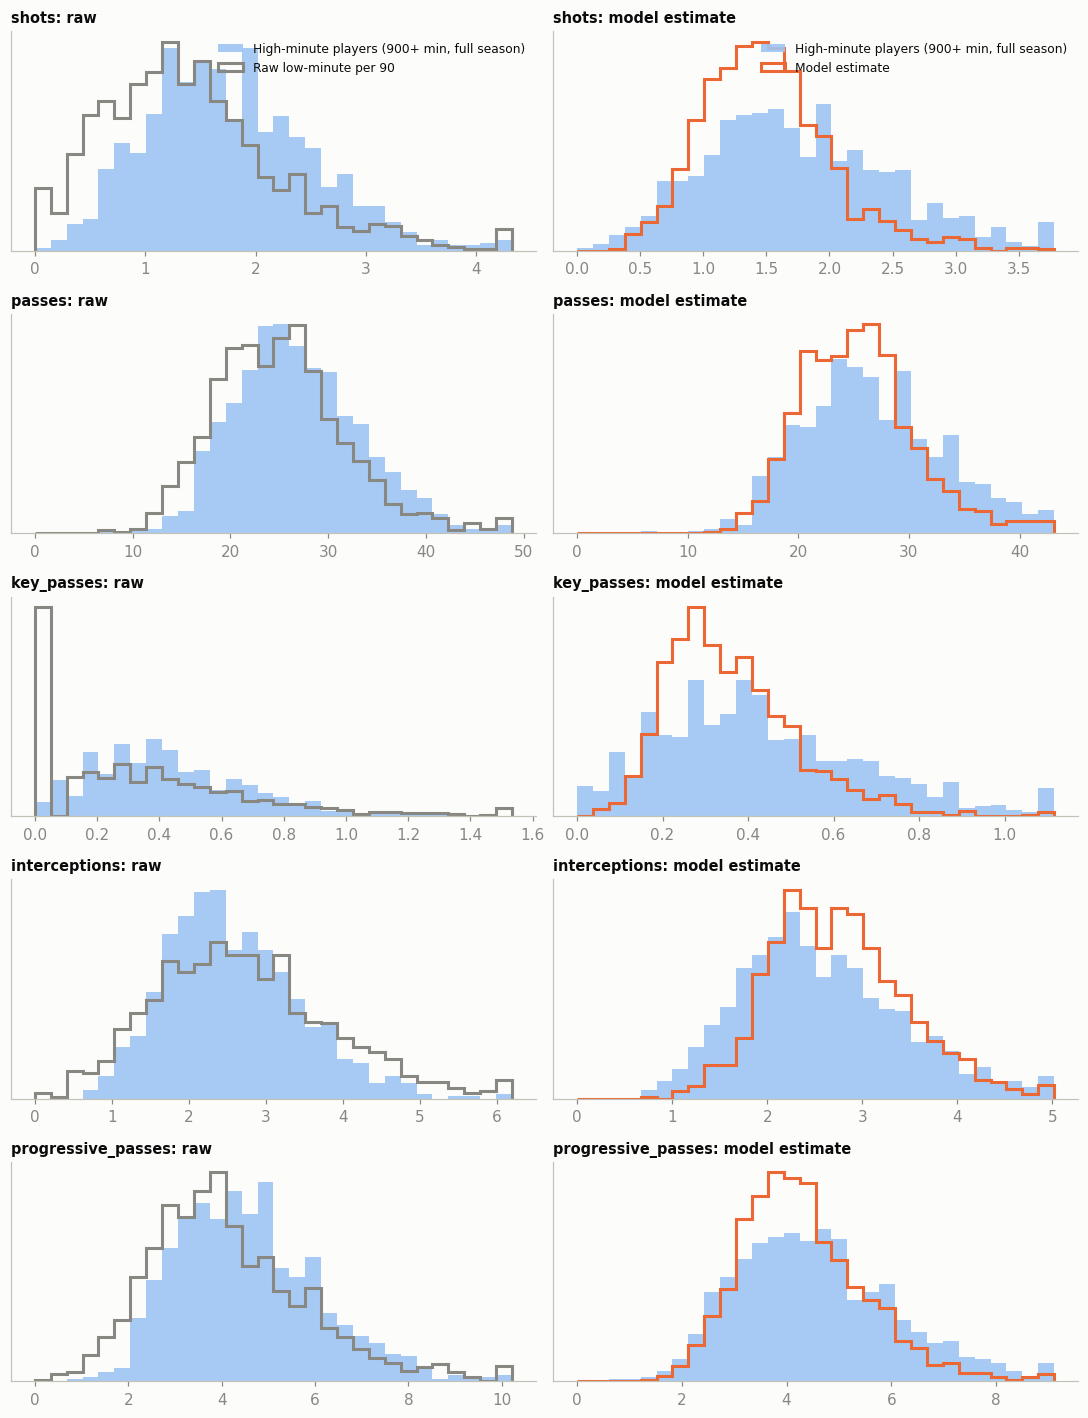

n    mean     sd  share_zero     p10  median  \
shots      high-minute      896.0   1.763  0.748       0.000   0.832   1.683   
           raw low-minute  1319.0   1.414  0.819       0.027   0.483   1.300   
           model estimate  1319.0   1.500  0.510       0.000   0.905   1.453   
passes     high-minute      896.0  26.805  6.394       0.000  18.912  26.199   
           raw low-minute  1319.0  25.071  6.780       0.000  16.984  24.647   
           model estimate  1319.0  25.404  5.228       0.000  19.292  25.058   
key_passes high-minute      896.0   0.432  0.243       0.018   0.155   0.396   
           raw low-minute  1319.0   0.342  0.339       0.290   0.000   0.284   
           model estimate  1319.0   0.360  0.152       0.000   0.195   0.334   

                              p90  
shots      high-minute      2.767  
           raw low-minute   2.448  
           model estimate   2.109  
passes     high-minute     35.476  
           raw low-minute  33.696  
           model estimate  31.828  
key_passes high-minute      0.762  
           raw low-minute   0.784  
           model estimate   0.563

In [7]:
stat_list = ["shots", "passes", "key_passes", "interceptions", "progressive_passes"]
stat_list = [s for s in stat_list if s in stems]
fig, axes = plt.subplots(len(stat_list), 2, figsize=(10, 2.6 * len(stat_list)))
for i, s in enumerate(stat_list):
    high = truth_seasons[f"full_{s}"]
    nh.overlay_hist(axes[i, 0], high, low[f"low_{s}"], "Raw low-minute per 90", nh.COLORS["raw"], title=f"{s}: raw")
    nh.overlay_hist(axes[i, 1], high, estimate[s], "Model estimate", nh.COLORS["ridge"], title=f"{s}: model estimate")
axes[0, 0].legend(fontsize=8, loc="upper right"); axes[0, 1].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()
display(pd.concat({s: nh.dist_summary({"high-minute": truth_seasons[f"full_{s}"], "raw low-minute": low[f"low_{s}"], "model estimate": estimate[s]})
                   for s in stat_list[:3]}).round(3))

These are two **different populations**: real low-minute players are not a random sample of players who would have played more (they are often bench players, or in a different role), so the estimate need not match the high-minute distribution. The model only knows the relationship learned from players who went on to play 900+ minutes, so for the bench-player population it is an extrapolation.

### Rates rebuilt from the estimates
A percentage the model never estimated directly, rebuilt from the estimated volumes, against the same rate from the raw low-minute volumes and from the high-minute players.

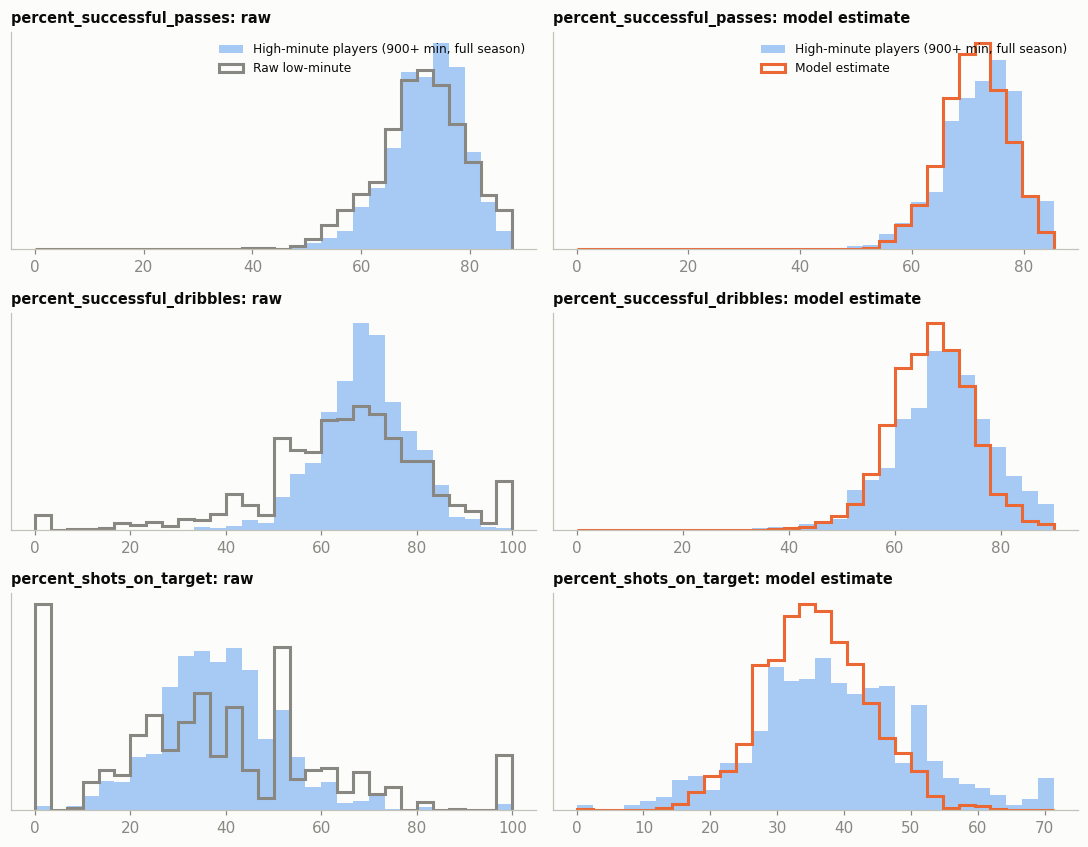

Share of low-minute players with the rate available (raw / estimate):


,raw,estimate
percent_successful_passes,1.000,1.0
percent_successful_dribbles,0.997,1.0
percent_shots_on_target,0.973,1.0


In [8]:
est_rates = am.rebuild(con, estimate, low, stems)
raw_vol = low[[f"low_{s}" for s in stems]].set_axis(stems, axis=1)
raw_rates = am.rebuild(con, raw_vol, low, stems)
tv = truth_seasons[[f"full_{s}" for s in stems]].set_axis(stems, axis=1)
high_rates = am.rebuild(con, tv, truth_seasons.assign(actual_minutes=truth_seasons["full_minutes"]), stems)
rate_names = [c for c in ["percent_successful_passes", "percent_successful_dribbles", "percent_shots_on_target"] if c in est_rates.columns]
fig, axes = plt.subplots(len(rate_names), 2, figsize=(10, 2.6 * len(rate_names)))
for i, c in enumerate(rate_names):
    nh.overlay_hist(axes[i, 0], high_rates[c].dropna(), raw_rates[c].dropna(), "Raw low-minute", nh.COLORS["raw"], title=f"{c}: raw")
    nh.overlay_hist(axes[i, 1], high_rates[c].dropna(), est_rates[c].dropna(), "Model estimate", nh.COLORS["ridge"], title=f"{c}: model estimate")
axes[0, 0].legend(fontsize=8, loc="upper right"); axes[0, 1].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()
print("Share of low-minute players with the rate available (raw / estimate):")
display(pd.DataFrame({"raw": raw_rates[rate_names].notna().mean(), "estimate": est_rates[rate_names].notna().mean()}).round(3))

### Individual players
A few real low-minute player-seasons: the raw per-90 and the model's estimate for three stats.

In [9]:
show = low[["short_name", "year", "actual_minutes"]].copy()
for s in ["shots", "key_passes", "interceptions"]:
    if s in stems:
        show[f"{s} raw"] = low[f"low_{s}"]
        show[f"{s} est"] = estimate[s]
display(show.sample(12, random_state=3).sort_values("actual_minutes").round(2).reset_index(drop=True))

,short_name,year,actual_minutes,shots raw,shots est,key_passes raw,key_passes est,interceptions raw,interceptions est
0,C. Dieye,2019,175.0,3.60,2.62,1.54,0.73,4.63,2.95
1,Parker Bowman,2025,240.0,1.88,1.56,0.38,0.35,2.25,2.20
2,J. Novoshelski,2022,257.0,1.75,1.60,0.00,0.27,3.85,3.01
3,J. Roddy,2022,285.0,1.58,1.40,0.32,0.41,2.21,2.71
4,M. Tavares,2023,300.0,0.30,0.88,0.30,0.32,3.30,2.78
5,T. Campbell,2024,347.0,2.07,1.75,0.52,0.47,2.33,2.52
6,A. Duran,2026,374.0,1.68,1.87,0.00,0.31,2.41,2.30
7,R. Cousino,2026,406.0,0.89,1.13,0.44,0.47,3.55,3.35
8,B. Meminger,2025,458.0,0.98,1.33,0.20,0.22,2.95,2.86
9,J. Maxwell,2025,633.0,1.56,1.63,0.00,0.19,3.98,3.27


## Using it on a new player
```python
from low_minute_player_analysis import apply_model as am, common
con = common.connect()
pool, stems = am.fit_data('male', 'Wingers')                          # training prefixes (900+ minute seasons)
low = am.low_minute_seasons(con, 'male', 'Wingers', stems)             # real low-minute player-seasons
est = am.predict(pool, low, stems)                                     # estimated full-season per-90 volumes
rates = am.rebuild(con, est, low, stems)                               # rates / percents rebuilt from them
```
`low` needs, per player-season: `actual_minutes`, `n_matches` and `low_<stat>` (the season's per-90 of every stat). Use one model per gender and position group, and keep minutes within the range the model saw (up to 750).

## Caveats
- The estimate is a conditional mean, so its spread is **narrower than the real high-minute distribution**; use it to rank and compare players, not to read off extremes.
- Validation used players who went on to play 900+ minutes; real low-minute players may differ, so the validated errors need not carry over.
- The truth contains the low-minute sample itself, which flatters the validation scores.
- Rebuilt percents are not clipped and can exceed 100; a rate is missing when its denominator is too small.